# Using Graph Coarsening to Make Caligraphy Images

- author: Zhifeng Wang
- date: y2025m06d07

In [1]:
import json as mod_json
import matplotlib.pyplot as mod_plt
import numpy as mod_np
import PIL.Image as mod_img
import subprocess as mod_subprocess

## Configs

This notebook uses my implementation of the graph coarsening program to apply special "visual effects" on the caligraphy graphs.

In [2]:
CONFIG_PROGRAM_COARSEN = "D:/repos/zhifeng_graph_util/target/release/zhifeng_coarsen_graph.exe"

In [3]:
S1_TO_ONE_COLOR_STR = "s1_one_color"
S2_MARK_SEP = "s2_sep"

In [4]:
s0_img_dir_path = "./workspace"
s0_img_name = "zhifeng-y2025m10d11-hlm_ch38_p05"
s0_img_ext = "png"

CONFIG_S3_DIR_SEP_CHAR_IMGS = f"{s0_img_dir_path}/s3_sep_char_imgs"
CONFIG_S4_DIR_GRAPHS = f"{s0_img_dir_path}/s4_graphs"
CONFIG_S5_DIR_GRAPHS = f"{s0_img_dir_path}/s5_graphs"

## Step 0: Make "One Color" Image

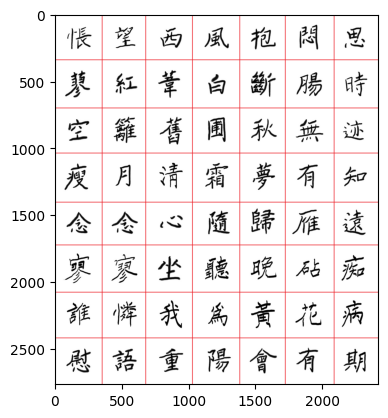

In [5]:
s0_img = mod_img.open(f"{s0_img_dir_path}/{s0_img_name}.{s0_img_ext}")
s0_img_data = mod_np.array(s0_img)

S0_ROW_NUM = s0_img_data.shape[0]
S0_COL_NUM = s0_img_data.shape[1]
mod_plt.imshow(s0_img_data)

In [6]:
CLOSE_TARGET_PIXEL_COLOR_NP_ARR = mod_np.array([3, 3, 3])

In [7]:
def make_close_pixels_bool_img(img_arr: mod_np.array, close_target_pixel: mod_np.array):

    def tell_is_pixel_close(query_pixel: mod_np.array):
        diff = 0
        for i in range(3):
            diff += abs(query_pixel[i] - close_target_pixel[i])
        
        return diff < 64

    ans_mark_arr = mod_np.zeros(img_arr.shape[:2],dtype=bool)
    for row_i, row in enumerate(img_arr):
        for col_i, pixel in enumerate(row):
            if (tell_is_pixel_close(pixel)):
                ans_mark_arr[row_i][col_i] = True
    return ans_mark_arr

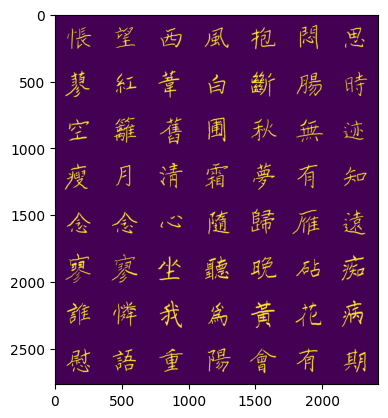

In [8]:
s0_close_arr = make_close_pixels_bool_img(s0_img_data, CLOSE_TARGET_PIXEL_COLOR_NP_ARR)
mod_plt.imshow(s0_close_arr)

In [9]:
def make_color_img_from_bool_img(bool_img: mod_np.array, pixel_0_color: mod_np.array, pixel_1_color: mod_np.array):
    ans_img_arr = mod_np.zeros([bool_img.shape[0], bool_img.shape[1], 4],dtype=mod_np.uint8)

    for row_i, row in enumerate(bool_img):
        for col_i, flag in enumerate(row):
            if (flag == True):
                ans_img_arr[row_i][col_i] = pixel_1_color
            else:
                ans_img_arr[row_i][col_i] = pixel_0_color

    return ans_img_arr

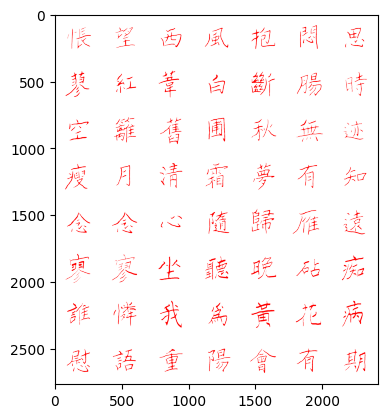

In [10]:
s0_clean_img = make_color_img_from_bool_img(s0_close_arr, [255,255,255,0], [255,0,0,255])

mod_plt.imshow(s0_clean_img)

In [11]:
mod_img.fromarray(s0_clean_img).save(f"{s0_img_dir_path}/{s0_img_name}-{S1_TO_ONE_COLOR_STR}.{s0_img_ext}")

## Step 1: Manually Mark Boundaries

## Step 2: Separate Characters

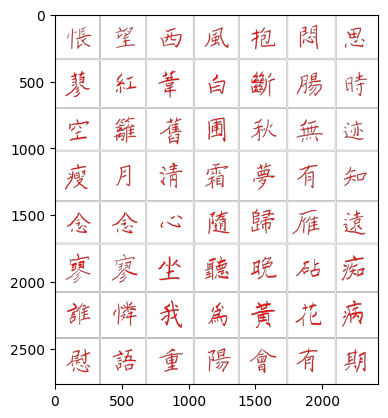

In [12]:
s2_img = mod_img.open(f"{s0_img_dir_path}/{s0_img_name}-{S2_MARK_SEP}.{s0_img_ext}")

mod_plt.imshow(s2_img)

In [13]:
CONFIG_BOUND_PIXEL = mod_np.array([255,255,255,255])
CONFIG_BACK_PIXEL = mod_np.array([0,0,0,0])
CONFIG_FRONT_PIXEL = mod_np.array([255,0,0,255])
CONFIG_BOUND_IDX = 0
CONFIG_BACK_IDX = 1
CONFIG_FRONT_IDX = 2

In [14]:
def make_info_img_from_s2_img(s2_img_arr: mod_np.array):
    shape = s2_img_arr.shape
    row_num = shape[0]
    col_num = shape[1]

    def tell_is_bound_pixel(pixel_ref: mod_np.array)->bool:
        return (pixel_ref == CONFIG_BOUND_PIXEL).all()

    def tell_is_front_pixel(pixel_ref: mod_np.array)->bool:
        return (pixel_ref == CONFIG_FRONT_PIXEL).all()


    ans_info_img = mod_np.zeros((row_num, col_num), dtype=mod_np.uint8)

    for row_i, row_arr_ref in enumerate(s2_img_arr):
        for col_i, pixel_ref in enumerate(row_arr_ref):
            if tell_is_bound_pixel(pixel_ref) == True:
                ans_info_img[row_i][col_i] = CONFIG_BOUND_IDX
            elif tell_is_front_pixel(pixel_ref) == True:
                ans_info_img[row_i][col_i] = CONFIG_FRONT_IDX
            else:
                ans_info_img[row_i][col_i] = CONFIG_BACK_IDX
    return ans_info_img

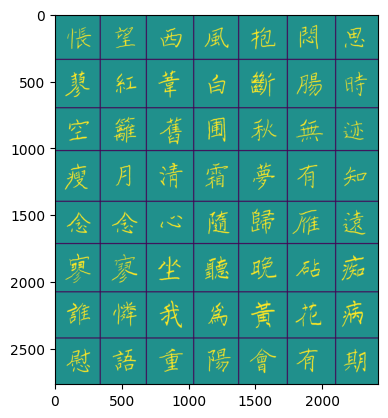

In [15]:
s3_info_img = make_info_img_from_s2_img(mod_np.array(s2_img))
mod_plt.imshow(s3_info_img)

In [20]:
CONFIG_ROW_HEIGHT = 346
CONFIG_MID_ROW_IDX = 173 #+ 3 * CONFIG_ROW_HEIGHT
CONFIG_MID_ROW_IDX

173

In [21]:
class CharacterSepIter:
    def __init__(self, s3_info_img):
        self.__info_img = s3_info_img
        self.__row_num = s3_info_img.shape[0]
        self.__col_num = s3_info_img.shape[1]
        self.__row_i = CONFIG_MID_ROW_IDX
        self.__col_i = 0
        self.__visit_flag_arr = mod_np.zeros((self.__row_num, self.__col_num), dtype=bool)

    def next(self):
        row_num = self.__row_num
        col_num = self.__col_num
        row_i = self.__row_i
        col_i = self.__col_i

        # print(row_num, row_i)

        if row_i >= row_num:
            return None

        info_img_ref = self.__info_img
        visit_flag_arr_ref = self.__visit_flag_arr

        while row_i < row_num and (info_img_ref[row_i][col_i] != CONFIG_FRONT_IDX or visit_flag_arr_ref[row_i][col_i] == True):
            col_i += 1
            if col_i >= col_num:
                row_i += CONFIG_ROW_HEIGHT
                col_i = 0

        if row_i >= row_num:
            self.__row_i = row_i
            self.__col_i = col_i
            return None
        
        def cord_to_idx(row_i, col_i):
            return row_i * col_num + col_i
        
        def idx_to_cord(idx: int) -> tuple[int, int]:
            return (idx // col_num, idx % col_num)

        front_q = []
        front_row_min = row_i
        front_col_min = col_i
        front_row_max = row_i
        front_col_max = col_i


        q: list[int] = [cord_to_idx(row_i, col_i)]

        while len(q) > 0:
            curr_idx = q.pop()
            curr_row_i, curr_col_i = idx_to_cord(curr_idx)

            if info_img_ref[curr_row_i][curr_col_i] == CONFIG_FRONT_IDX:
                front_row_min = min(front_row_min, curr_row_i)
                front_col_min = min(front_col_min, curr_col_i)
                front_row_max = max(front_row_max, curr_row_i)
                front_col_max = max(front_col_max, curr_col_i)
                front_q.append(curr_idx)
            
            next_row_i = curr_row_i - 1
            next_col_i = curr_col_i
            if curr_row_i > 0 and info_img_ref[next_row_i][next_col_i] != CONFIG_BOUND_IDX and visit_flag_arr_ref[next_row_i][next_col_i] == False:
                q.append(cord_to_idx(next_row_i, next_col_i))
                visit_flag_arr_ref[next_row_i][next_col_i] = True

            next_row_i = curr_row_i + 1
            next_col_i = curr_col_i
            if curr_row_i + 1 < row_num and info_img_ref[next_row_i][next_col_i] != CONFIG_BOUND_IDX and visit_flag_arr_ref[next_row_i][next_col_i] == False:
                q.append(cord_to_idx(next_row_i, next_col_i))
                visit_flag_arr_ref[next_row_i][next_col_i] = True

            next_row_i = curr_row_i
            next_col_i = curr_col_i - 1
            if curr_col_i > 0 and info_img_ref[next_row_i][next_col_i] != CONFIG_BOUND_IDX and visit_flag_arr_ref[next_row_i][next_col_i] == False:
                q.append(cord_to_idx(next_row_i, next_col_i))
                visit_flag_arr_ref[next_row_i][next_col_i] = True

            next_row_i = curr_row_i
            next_col_i = curr_col_i + 1
            if curr_col_i + 1 < col_num and info_img_ref[next_row_i][next_col_i] != CONFIG_BOUND_IDX and visit_flag_arr_ref[next_row_i][next_col_i] == False:
                q.append(cord_to_idx(next_row_i, next_col_i))
                visit_flag_arr_ref[next_row_i][next_col_i] = True

        ANS_IMG_BOUND = 12

        ans_img_row_num = front_row_max - front_row_min + ANS_IMG_BOUND + ANS_IMG_BOUND
        ans_img_col_num = front_col_max - front_col_min + ANS_IMG_BOUND + ANS_IMG_BOUND

        ans_bool_img = mod_np.zeros((ans_img_row_num, ans_img_col_num), dtype=bool)

        for curr_idx in front_q:
            curr_row_i, curr_col_i = idx_to_cord(curr_idx)
            ans_row_i = curr_row_i - front_row_min + ANS_IMG_BOUND
            ans_col_i = curr_col_i - front_col_min + ANS_IMG_BOUND

            ans_bool_img[ans_row_i][ans_col_i] = True
        
        self.__row_i = row_i
        self.__col_i = col_i

        return ans_bool_img
    
    def check(self):
        return mod_plt.imshow(self.__visit_flag_arr)
    

## Extract Character Images

In [22]:
sep_iter = CharacterSepIter(mod_np.array(s3_info_img))

In [23]:
def make_s3_sep_char_img_path(img_i: int):
    return f"{CONFIG_S3_DIR_SEP_CHAR_IMGS}/{str(img_i).zfill(3)}.png"

In [24]:
img_i = 0

while True:
    sep_img = sep_iter.next()
    if sep_img is None:
        break
    color_img = make_color_img_from_bool_img(sep_img, [255,255,255,0], [255,0,0,255])

    mod_img.fromarray(color_img).save(make_s3_sep_char_img_path(img_i))
    img_i += 1


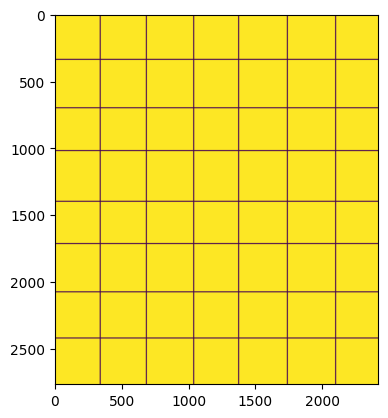

In [25]:
sep_iter.check()

## Generate Graphs

In [26]:
def make_bool_img_from_color_img(color_img: mod_np.array, pixel_1_color: mod_np.array):
    ans_img_arr = mod_np.zeros((color_img.shape[0], color_img.shape[1]),dtype=mod_np.uint8)

    for row_i, row in enumerate(color_img):
        for col_i, pixel in enumerate(row):
            if (pixel == pixel_1_color).all():
                ans_img_arr[row_i][col_i] = True
            else:
                ans_img_arr[row_i][col_i] = False

    return ans_img_arr

In [27]:
def make_graph_from_bool_img(bool_img: mod_np.array):
    
    row_num = bool_img.shape[0]
    col_num = bool_img.shape[1]

    def cord_to_idx(row_i, col_i):
        return row_i * col_num + col_i

    node_num = 0
    graph_edge_list = []
    node_pos_list = []

    cord_idx_to_graph_idx_map: dict[int, int] = {}

    for row_i, row in enumerate(bool_img):
        for col_i, flag in enumerate(row):

            if flag == False:
                continue
            
            curr_idx = cord_to_idx(row_i, col_i)
            cord_idx_to_graph_idx_map[curr_idx] = node_num

            node_pos_list.append(row_i)
            node_pos_list.append(col_i)

            node_num += 1

    for row_i, row in enumerate(bool_img):
        for col_i, flag in enumerate(row):
            

            if flag == False:
                continue

            curr_cord_idx = cord_to_idx(row_i, col_i)
            curr_graph_idx = cord_idx_to_graph_idx_map[curr_cord_idx]

            if col_i + 1 < col_num and bool_img[row_i][col_i + 1] == True:
                next_cord_idx = cord_to_idx(row_i, col_i + 1)
                next_graph_idx = cord_idx_to_graph_idx_map[next_cord_idx]

                graph_edge_list.append(curr_graph_idx)
                graph_edge_list.append(next_graph_idx)

            if row_i + 1 < row_num and bool_img[row_i + 1][col_i] == True:
                next_cord_idx = cord_to_idx(row_i + 1, col_i)
                next_graph_idx = cord_idx_to_graph_idx_map[next_cord_idx]

                graph_edge_list.append(curr_graph_idx)
                graph_edge_list.append(next_graph_idx)
    
    return {"index": graph_edge_list, "position": {"dim": 2, "data": node_pos_list}}




In [28]:

GRAPH_NUM = 56

def make_s4_graph_path(idx: int) -> str:
    return f"{CONFIG_S4_DIR_GRAPHS}/{str(idx).zfill(3)}-g0.json"

In [29]:
for img_i in range(GRAPH_NUM):
    sep_char_img_path = make_s3_sep_char_img_path(img_i)
    img = mod_img.open(sep_char_img_path)

    bool_img = make_bool_img_from_color_img(mod_np.array(img), [255,0,0,255])

    graph_dict = make_graph_from_bool_img(bool_img)
    
    mod_json.dump(graph_dict, open(make_s4_graph_path(img_i), "w"))
    

## Graph Coarsen

In [30]:
def make_s5_graph_path(idx: int, level: int) -> str:
    return f"{CONFIG_S5_DIR_GRAPHS}/{str(idx).zfill(3)}-g{level}.json"

In [31]:
for img_i in range(GRAPH_NUM):

    mod_subprocess.run([CONFIG_PROGRAM_COARSEN, 
                make_s4_graph_path(img_i),
                make_s5_graph_path(img_i, 1)])

In [33]:
def coarsen_all(level_i):
    for img_i in range(GRAPH_NUM):

        mod_subprocess.run([CONFIG_PROGRAM_COARSEN, 
                    make_s5_graph_path(img_i, level_i),make_s5_graph_path(img_i, level_i + 1)])

In [34]:
coarsen_all(1)
coarsen_all(2)
coarsen_all(3)

## Step 6: Make Final Image

In [35]:
class Img2DHelper:
    def __init__(self, height_int, width_int):
        self.img_arr = mod_np.zeros((height_int,width_int,4),dtype = mod_np.uint8)
        for row_i in range(0, height_int):
            for col_i in range(0, width_int):
                self.img_arr[row_i][col_i][3] = 255
        self.row_num = height_int
        self.col_num = width_int

    def draw_line(self, begin_row_i, begin_col_i, end_row_i, end_col_i, color_fn):
        row_delta = end_row_i - begin_row_i
        col_delta = end_col_i - begin_col_i

        row_delta_abs = mod_np.abs(row_delta)
        col_delta_abs = mod_np.abs(col_delta)

        if row_delta == 0 and col_delta == 0:
            return
        
        row_delta_sign = 1
        if row_delta < 0:
            row_delta_sign = -1

        col_delta_sign = 1
        if col_delta < 0:
            col_delta_sign = -1


        if row_delta_abs > col_delta_abs:
            for row_off_i in range(0, row_delta_abs):
                
                row_i = int(round(begin_row_i + row_off_i * row_delta_sign))
                col_i = int(round(begin_col_i +  (row_off_i * col_delta / row_delta_abs)))

                if row_i >= self.row_num or row_i < 0 or col_i >= self.col_num or col_i < 0:
                    continue
                self.img_arr[row_i][col_i] = color_fn(row_i, col_i, row_off_i / row_delta_abs)

        else:
            for col_off_i in range(0, col_delta_abs):
                
                row_i = int(round(begin_row_i +  (col_off_i *row_delta/ col_delta_abs)))
                col_i = int(round(begin_col_i + col_off_i * col_delta_sign))

                if row_i >= self.row_num or row_i < 0 or col_i >= self.col_num or col_i < 0:
                    continue
                self.img_arr[row_i][col_i] = color_fn(row_i, col_i, col_off_i / col_delta_abs)

    def save_to_file(self, file_path):
        img = mod_img.fromarray(self.img_arr)
        img.save(file_path)

## Custom Sceen Config

In [36]:
C_SQUARE_LEN = 172
C_SQUARE_HALF = C_SQUARE_LEN // 2

C_IMG_ROW_NUM = 172 * 7
C_IMG_COL_NUM = 172 * 8

C_LEFT_PAD = 0
C_TOP_PAD = C_LEFT_PAD

C_ROW_NUM = 7
C_COL_NUM = 8

## Phone Screen Config

In [ ]:
C_IMG_ROW_NUM = 2622
C_IMG_COL_NUM = 1206

C_LEFT_PAD = 3
C_TOP_PAD = 291
C_SQUARE_LEN = 120
C_SQUARE_HALF = C_SQUARE_LEN // 2

C_ROW_NUM = 17
C_COL_NUM = 10

## Computer Screen Config

In [42]:
C_IMG_ROW_NUM = 1600
C_IMG_COL_NUM = 2560

C_LEFT_PAD = 5
C_TOP_PAD = 0
C_SQUARE_LEN = 150
C_SQUARE_HALF = C_SQUARE_LEN // 2

C_ROW_NUM = 10
C_COL_NUM = 17

## Sequence Config

In [37]:
def calc_row_col_pos(idx: int) -> tuple[int, int]:
    return (idx % C_ROW_NUM, C_COL_NUM - 1 - (idx // C_ROW_NUM))

## Color Config

In [38]:
def color_fn(a, b, c):
    return [255,0,0x7f, 255]

In [39]:
C_ZOOM_FACTOR = 0.7

## Utilities

In [40]:
def calc_pos_min_and_max(position_arr: list[int]):

    min_row_i = position_arr[0]
    max_row_i = position_arr[0]
    min_col_i = position_arr[1]
    max_col_i = position_arr[1]

    for i in range(2, len(position_arr), 2):
        min_row_i = min(min_row_i, position_arr[i])
        max_row_i = max(max_row_i, position_arr[i])
        min_col_i = min(min_col_i, position_arr[i + 1])
        max_col_i = max(max_col_i, position_arr[i + 1])

    return (min_row_i, max_row_i, min_col_i, max_col_i)

In [41]:
def calc_square_center(pos_tuple: tuple[int, int]):
    row_i, col_i = pos_tuple
    return (C_TOP_PAD + C_SQUARE_HALF + row_i * C_SQUARE_LEN, C_LEFT_PAD + C_SQUARE_HALF + col_i * C_SQUARE_LEN)

## Make Image

In [42]:
ans_img_helper = Img2DHelper(C_IMG_ROW_NUM, C_IMG_COL_NUM)

In [43]:
for img_i in range(GRAPH_NUM):
    graph_dict = mod_json.load(open(make_s5_graph_path(img_i,3)))
    edge_list = graph_dict["index"]
    pos = graph_dict["position"]["data"]

    (min_row_i, max_row_i, min_col_i, max_col_i) = calc_pos_min_and_max(pos)

    mid_row_i = (max_row_i + min_row_i) // 2
    mid_col_i = (max_col_i + min_col_i) // 2

    target_mid_row_i, target_mid_col_i = calc_square_center(calc_row_col_pos(img_i))

    for i in range(0, len(edge_list), 2):
        node_0_i = edge_list[i]
        node_1_i = edge_list[i + 1]

        node_0_row_i = (pos[node_0_i * 2] - mid_row_i) * C_ZOOM_FACTOR + target_mid_row_i
        node_0_col_i = (pos[node_0_i * 2 + 1] - mid_col_i) * C_ZOOM_FACTOR + target_mid_col_i

        node_1_row_i = (pos[node_1_i * 2] - mid_row_i) * C_ZOOM_FACTOR + target_mid_row_i
        node_1_col_i = (pos[node_1_i * 2 + 1] - mid_col_i) * C_ZOOM_FACTOR + target_mid_col_i

        ans_img_helper.draw_line(int(node_0_row_i), int(node_0_col_i), int(node_1_row_i), int(node_1_col_i), color_fn)
    
    # print(len(pos), min_row_i, max_row_i, min_col_i, max_col_i)

In [44]:
ans_img_helper.save_to_file("test-5.png")